# Notebook 01 - Replica baseline y evaluacion del modelo logistico

## Objetivos
- Replicar un baseline de clasificacion para riesgo de cancer de pulmon con datos sinteticos de Synthea.
- Construir un flujo reproducible de carga, preprocesamiento, seleccion de variables y entrenamiento.
- Evaluar el rendimiento con conjunto de test y validacion anidada.
- Interpretar el modelo mediante coeficientes y visualizacion de variables relevantes.

## Resumen de secciones y celdas

| Seccion | Objetivo | Celdas (aprox.) |
|---|---|---|
| Setup de entorno y datos | Importar librerias, fijar rutas y descargar dataset si no existe | 2-7 |
| Preparacion del dataset | Crear DataFrame, identificar target y separar train/test | 8-18 |
| Pipeline baseline | Definir preprocesamiento, seleccion y modelo logistico inicial | 19-25 |
| Validacion anidada | Comparar rendimiento segun numero de variables y mostrar curva de seleccion | 26-27 |
| Curvas de evaluacion | Analizar curvas ROC y Precision-Recall del modelo | 28-34 |
| Interpretabilidad | Extraer y visualizar variables mas influyentes segun coeficientes | 35-42 |

## Nota metodologica
- El notebook sigue una secuencia lineal: setup, datos, modelado, validacion y explicabilidad.

In [3]:
import sys
print(sys.executable)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Scripts\python.exe


# Importacion de librerías, definición de raíz del proyecto y descarga de datos (setup)

In [1]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegressionCV
from sklearn.inspection import permutation_importance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest
from joblib import Memory
import tempfile
import shutil

Vamos a definir la raíz del proyecto y evitar rutas absolutas.

In [2]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")

DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


Comprobamos que el archivo existe y si no es así lo descargamos automáticamente.

In [3]:
DATA_URL = "https://data.mendeley.com/public-files/datasets/b24cb4nn8h/files/94aa2cf6-b4c1-4140-bfcc-d21040a14735/file_downloaded"
FILE_PATH = DATA_DIR / "synthea_30k.csv"

DATA_DIR.mkdir(parents = True ,exist_ok = True )

if not FILE_PATH.exists():
    print("Descargando dataset...")
    response = requests.get(DATA_URL)
    with open(FILE_PATH, 'wb') as f:
        f.write(response.content)
    print("Descarga completada.")
else:
    print("Dataset ya disponible localmente.")

Dataset ya disponible localmente.


# Creación de DataFrame y división de los datos

In [4]:
datos = pd.read_csv(FILE_PATH, low_memory=False)

In [5]:
datos.shape

(4221, 765)

In [6]:
datos.head()

,ptnum,label,scc,C-44465007,C-392091000,C-248595008,C-6246-3,C-197927001,C-234262008,C-389221,...,C-274804006,C-38822007,C-704-7,C-72514-3,C-6844-5,C-268556000,C-979492,C-122548005,C-141918,C-1359133
0,p15865,1,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
1,p27452,1,145,True,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN
2,p12382,1,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
3,p21814,1,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
4,p2902,1,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN


Lo primero que nos llama la atención es la cantidad de datos faltantes y la enorme cantidad de variables. Para entender mejor cuales son estas variables recurrimos al repositorio GitHub del autor (https://github.com/lhs-open/synthetic-data/blob/main/lung-cancer-risk/synthea-lc-dataset-codes.csv) Donde en el archivo csv, da nombre a cada una de las variables. La codificación de estos nombres es la habitual en proyectos médicos y es el original standard code (SNOMED-CT, LOINC, etc.) precedido por 'C-' (Información extraida del readme del repositorio).

Gracias a esta información nos damos cuenta que es normal que falten tantos datos y es que se recoge información de enfermedades tan espécificas como un esguice de tobillo, la cual la mayoría de paciente no ha sufrido o puede que la haya sufrido pero no este recogido en los datos.

Sea como sea, es inviable trabajar con tantas variables con datos faltantes, haremos primero la selección de las 50 mejores variables para trabajar de una manera más eficiente. Pero antes, debemos de identificar la variable objetivo.

In [7]:
columnas_C = datos.filter(regex='^C-')
datos.drop(columnas_C,axis=1)

,ptnum,label,scc
0,p15865,1,150
1,p27452,1,145
2,p12382,1,133
3,p21814,1,132
4,p2902,1,127
...,...,...,...
4216,p9457,0,100
4217,p967,0,100
4218,p9736,0,100
4219,p9788,0,100


Extrayendo todas las columnas que empiezan por "C-". Nos quedamos únicamente con tres atributos, el identificador del paciente, una variable binaria y lo que parece ser otra de las variables explicativas `scc`. En este punto es fácil detectar que la variable que mide la presencia o no de cancér de pulmón es `label`, es decir, nuestra variable objetivo (target). 

In [8]:
datos=datos.rename(columns={'label': 'target'})
datos=datos.set_index("ptnum")

In [9]:
X= datos.drop("target",axis=1)
y=datos["target"]
X.head()

,scc,C-44465007,C-392091000,C-248595008,C-6246-3,C-197927001,C-234262008,C-389221,C-92691004,C-392021009,...,C-274804006,C-38822007,C-704-7,C-72514-3,C-6844-5,C-268556000,C-979492,C-122548005,C-141918,C-1359133
ptnum,,,,,,,,,,,,,,,,,,,,,
p15865,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
p27452,145,True,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN
p12382,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
p21814,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
p2902,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=625, stratify=y)


# Creación de pipelines de preprocesado y modelado

In [11]:
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer


cat_pipeline = Pipeline([
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ("imputer",SimpleImputer(strategy="constant", fill_value=0.0,keep_empty_features=True)),
])

preprocesamiento = ColumnTransformer([
    ("cat", cat_pipeline, make_column_selector(dtype_include="object")),
], remainder=(SimpleImputer(strategy="constant", fill_value=0.0)), verbose_feature_names_out=False)

seleccion = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("50mejores", SelectKBest(k=100)),
])

regresor = Pipeline([
    ("seleccion", seleccion),
    ("logistic_regression", LogisticRegressionCV(max_iter=1000, n_jobs=-1,scoring="recall", cv=5,random_state=625)),
])


In [12]:
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer


cat_pipeline = Pipeline([
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ("imputer",SimpleImputer(strategy="constant", fill_value=0.0,keep_empty_features=True)),
])

num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="constant", fill_value=0.0,keep_empty_features=True)),
    ("scaler", StandardScaler())
])

preprocesamiento = ColumnTransformer([
    ("cat", cat_pipeline, make_column_selector(dtype_include="object")),
    ("num", num_pipeline,make_column_selector(dtype_exclude="object"))
], remainder=(SimpleImputer(strategy="constant", fill_value=0.0)), verbose_feature_names_out=False)

seleccion = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("50mejores", SelectKBest(k=50)),
])

regresor = Pipeline([
    ("seleccion", seleccion),
    ("logistic_regression", LogisticRegressionCV(max_iter=1000, n_jobs=-1,scoring="recall", cv=5,random_state=625)),
])


In [13]:
modelo=regresor.fit(X_train, y_train)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [  0   1   2   3   4   5   6   7   8   9  10  11  12  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  34  35  37  38
  39  42  43  44  45  46  47  48  49  51  52  53  54  57  58  59  61  62
  63  64  65  66  67  68  69  70  71  72  73  74  75  76  77  80  81  82
  83  84  85  86  87  88  90  91  92  93  94  95  96  97  98  99 100 101
 102 103 104 105 106 107 108 110 111 112 113 114 115 116 117 118 119 120
 121 122 123 124 125 126 127 128 129 130 132 133 134 135 136 137 138 139
 140 141 142 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157
 158 159 161 162 163 164 165 166 167 168 169 172 173 174 175 176 177 178
 179 180 181 182 183 184 185 188 189 190 191 192 193 194 195 196 197 198
 199 200 201 202 203 204 205 206 207 208 209 210 211 212 214 215 216 217
 218 21

In [14]:
y_pred=modelo.predict(X_test)


In [15]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       307
           1       0.98      0.93      0.96       116

    accuracy                           0.98       423
   macro avg       0.98      0.96      0.97       423
weighted avg       0.98      0.98      0.98       423



In [ ]:
from sklearn.metrics import roc_auc_score
y_pred_proba = modelo.predict_proba(X_test)[:, 1]

auc_train = roc_auc_score(y_test, y_pred_proba)
print(f"AUC en Test: {auc_train}")

# Cross-validation

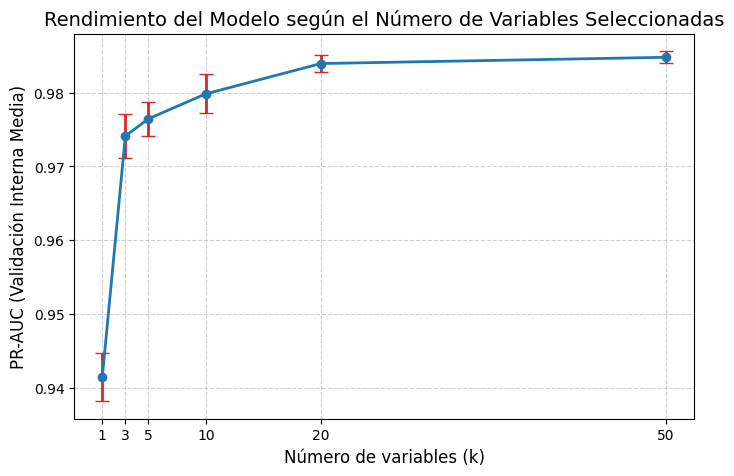

In [ ]:
cachedir = tempfile.mkdtemp()
mem = Memory(location=cachedir, verbose=0)

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=625)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("seleccion", SelectKBest()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=625, class_weight='balanced'))
], memory=mem)

param_grid = {
    'seleccion__k': [1,3,5,10,20,50],
    'logreg__C': [0.01, 0.1, 1.0, 10.0]
}

clf = GridSearchCV(
    estimator=pipeline, 
    param_grid=param_grid, 
    cv=inner_cv, 
    scoring='average_precision', 
    n_jobs=-1
)

nested_cv_results = cross_validate(
    estimator=clf, 
    X=X_train, 
    y=y_train, 
    cv=outer_cv, 
    return_estimator=True,
    n_jobs=-1
)

resultados_detallados = []

for i, grid_busqueda in enumerate(nested_cv_results['estimator']):
    df_cv = pd.DataFrame(grid_busqueda.cv_results_)
    
    for k in param_grid['seleccion__k']:
        res_k = df_cv[df_cv['param_seleccion__k'] == k]
        mejor_score_interno = res_k['mean_test_score'].max()
        
        resultados_detallados.append({
            'fold_externo': i,
            'k': k,
            'score': mejor_score_interno
        })

df_final = pd.DataFrame(resultados_detallados)

df_resumen = df_final.groupby('k')['score'].agg(['mean', 'std']).reset_index()

def plot_comparativa_k(df):
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        df['k'], 
        df['mean'], 
        yerr=df['std'], 
        fmt='-o', 
        capsize=5, 
        linewidth=2, 
        color='#1f77b4', 
        ecolor='#d62728'
    )
    plt.title('Rendimiento del Modelo segun el Numero de Variables Seleccionadas', fontsize=14)
    plt.xlabel('Numero de variables (k)', fontsize=12)
    plt.ylabel('PR-AUC (Validacion Interna Media)', fontsize=12)
    plt.xticks(df['k'])
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

plot_comparativa_k(df_resumen)

shutil.rmtree(cachedir)

Mostraremos las curvas ROC con una sola variable y con 50

## Curvas ROC

### Modelo con una variable

In [17]:
seleccion = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("50mejores", SelectKBest(k=1)),
])
regresor = Pipeline([
    ("seleccion", seleccion),    
    ("logistic_regression", LogisticRegressionCV(max_iter=1000, n_jobs=-1,scoring="recall", cv=5,random_state=625))]
)
modelo=regresor.fit(X_train, y_train)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [  0   1   2   3   4   5   6   7   8   9  10  11  12  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  34  35  37  38
  39  42  43  44  45  46  47  48  49  51  52  53  54  57  58  59  61  62
  63  64  65  66  67  68  69  70  71  72  73  74  75  76  77  80  81  82
  83  84  85  86  87  88  90  91  92  93  94  95  96  97  98  99 100 101
 102 103 104 105 106 107 108 110 111 112 113 114 115 116 117 118 119 120
 121 122 123 124 125 126 127 128 129 130 132 133 134 135 136 137 138 139
 140 141 142 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157
 158 159 161 162 163 164 165 166 167 168 169 172 173 174 175 176 177 178
 179 180 181 182 183 184 185 188 189 190 191 192 193 194 195 196 197 198
 199 200 201 202 203 204 205 206 207 208 209 210 211 212 214 215 216 217
 218 21

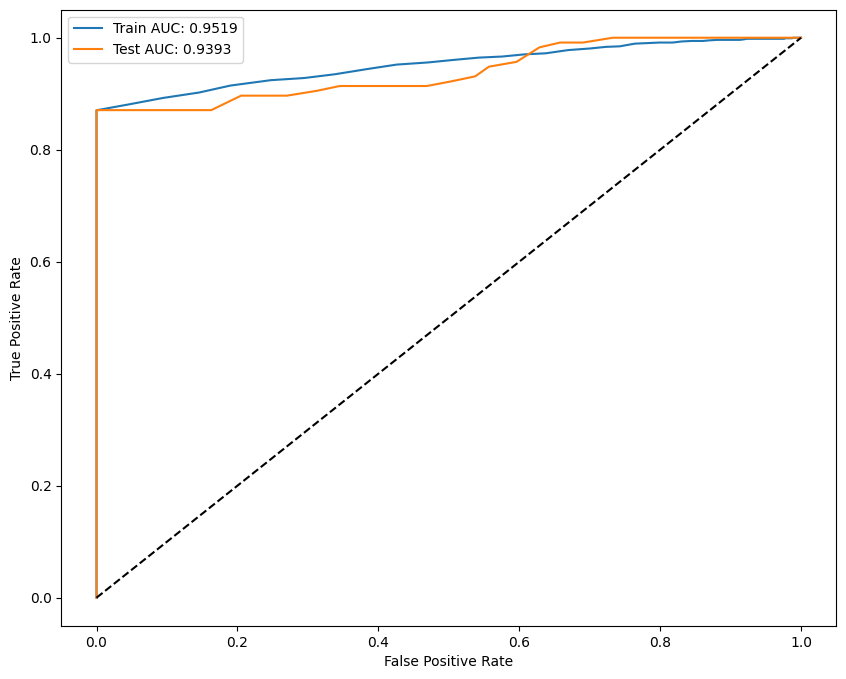

In [18]:
from sklearn.metrics import roc_curve, auc

probs_train = modelo.predict_proba(X_train)[:, 1]
probs_test = modelo.predict_proba(X_test)[:, 1]

fpr_train, tpr_train, _ = roc_curve(y_train, probs_train)
fpr_test, tpr_test, _ = roc_curve(y_test, probs_test)

plt.figure(figsize=(10, 8))
plt.plot(fpr_train, tpr_train, label=f'Train AUC: {auc(fpr_train, tpr_train):.4f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC: {auc(fpr_test, tpr_test):.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [19]:
from sklearn.metrics import precision_recall_curve, average_precision_score

ap_train = average_precision_score(y_train, probs_train)
ap_test = average_precision_score(y_test, probs_test)

prec_train, rec_train, _ = precision_recall_curve(y_train, probs_train)
prec_test, rec_test, _ = precision_recall_curve(y_test, probs_test)


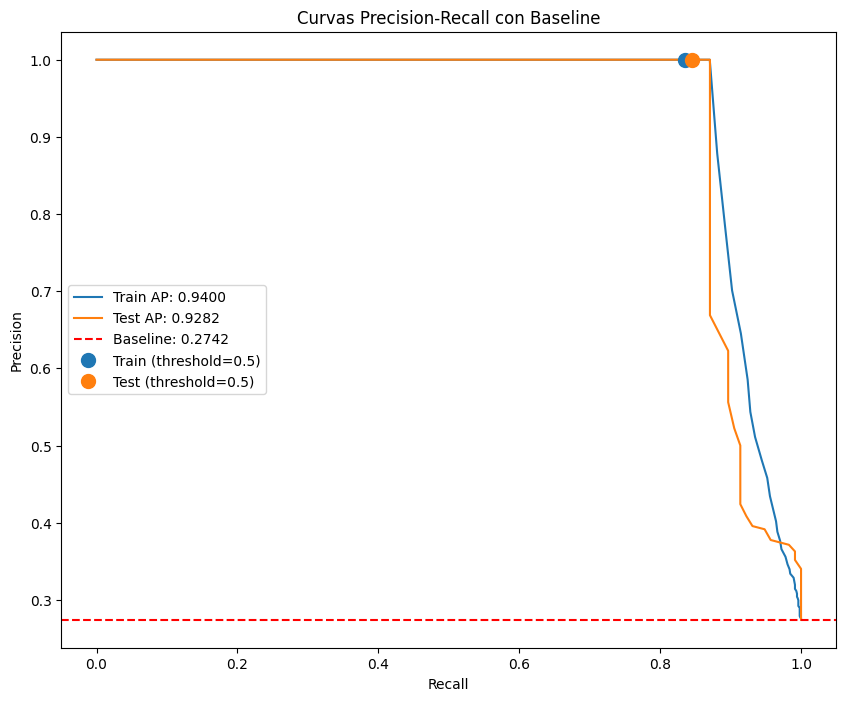

In [ ]:
from sklearn.metrics import precision_score, recall_score

y_pred_train_threshold = (probs_train >= 0.5).astype(int)
y_pred_test_threshold = (probs_test >= 0.5).astype(int)

prec_train_current = precision_score(y_train, y_pred_train_threshold)
rec_train_current = recall_score(y_train, y_pred_train_threshold)
prec_test_current = precision_score(y_test, y_pred_test_threshold)
rec_test_current = recall_score(y_test, y_pred_test_threshold)

baseline = sum(y_test) / len(y_test)

plt.figure(figsize=(10, 8))
plt.plot(rec_train, prec_train, label=f'Train AP: {ap_train:.4f}')
plt.plot(rec_test, prec_test, label=f'Test AP: {ap_test:.4f}')

plt.axhline(y=baseline, color='red', linestyle='--', label=f'Baseline: {baseline:.4f}')

plt.plot(rec_train_current, prec_train_current, 'o', markersize=10, color='#1f77b4', label='Train (threshold=0.5)')
plt.plot(rec_test_current, prec_test_current, 'o', markersize=10, color='#ff7f0e', label='Test (threshold=0.5)')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curvas Precision-Recall con Baseline')
plt.legend()
plt.show()


# Variables más importantes

Al tratarse de un modelo logístico, que es intrínsecamente explicable, podemos extraer directamente de los coeficientes la importancia de las variables.

In [ ]:
reg_log=modelo.named_steps["logistic_regression"]
seleccion = modelo.named_steps['seleccion']
preprocesado = seleccion.named_steps['preprocesamiento']
kbest = seleccion.named_steps['50mejores']

In [ ]:
nombres_todas = preprocesado.get_feature_names_out()
nombres_seleccionadas = nombres_todas[kbest.get_support()]
coeficientes = reg_log.coef_[0]

In [ ]:
df_coefs = pd.DataFrame({
    'Variable': nombres_seleccionadas,
    'Coeficiente': coeficientes
})

In [ ]:
df_coefs['Magnitud'] = df_coefs['Coeficiente'].abs()
top20 = df_coefs.sort_values(by='Magnitud', ascending=False).head(20)

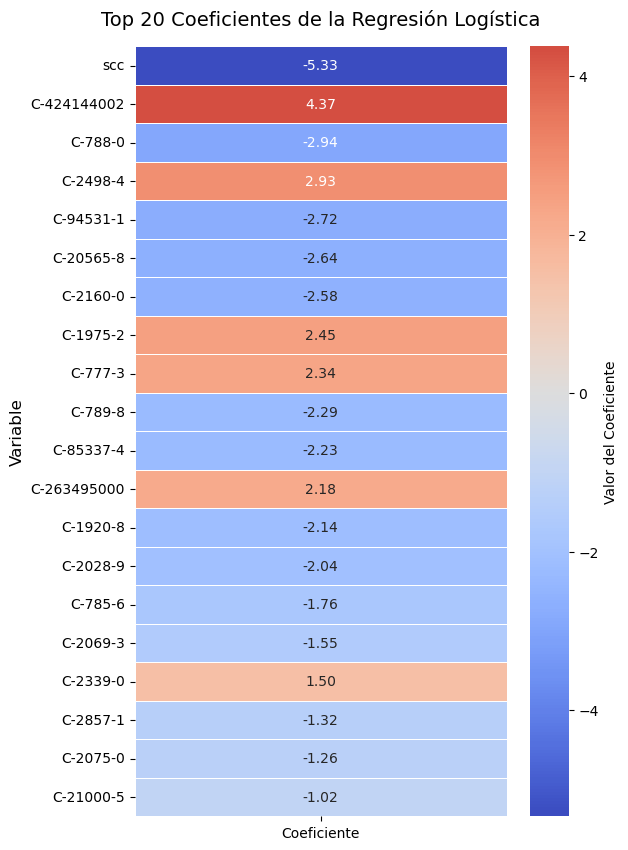

In [ ]:
heatmap_data = top20.set_index('Variable')[['Coeficiente']]
plt.figure(figsize=(6, 10))
sns.heatmap(data=heatmap_data, 
            annot=True,               
            fmt=".2f",               
            cmap="coolwarm",          
            center=0,                 
            linewidths=0.5,           
            cbar_kws={'label': 'Valor del Coeficiente'}) 
plt.title('Top 20 Coeficientes de la Regresión Logística', fontsize=14, pad=15)
plt.ylabel('Variable', fontsize=12)
plt.xlabel('')  
plt.show()

In [ ]:
top20

,Variable,Coeficiente,Magnitud
39,scc,-5.334597,5.334597
2,C-424144002,4.373254,4.373254
10,C-788-0,-2.940684,2.940684
34,C-2498-4,2.930859,2.930859
17,C-94531-1,-2.724300,2.724300
31,C-20565-8,-2.635084,2.635084
30,C-2160-0,-2.582525,2.582525
32,C-1975-2,2.450982,2.450982
16,C-777-3,2.339088,2.339088
11,C-789-8,-2.294406,2.294406
